# Part B (03): Hyperparameter experiments (validation set only)
Models: **Logistic Regression** and **KNN**, each on 3 feature sets (raw, color histogram, PCA).



In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

SEED = 12
CACHE = Path("../cache")
EXP = Path("../experiments"); EXP.mkdir(exist_ok=True)

imgs = np.load(CACHE / "images_uint8.npz")
feats = np.load(CACHE / "features.npz")
CLASSES = list(imgs["classes"])

def to_raw(X):
    return X.reshape(len(X), -1).astype(np.float32) / 255.0


FS = {
    "raw":  (to_raw(imgs["X_train"]), to_raw(imgs["X_val"])),
    "hist": (feats["H_train"], feats["H_val"]),
    "pca":  (feats["P_train"], feats["P_val"]),
}
y_train, y_val = feats["y_train"], feats["y_val"]
print({k: v[0].shape[1] for k, v in FS.items()}, len(y_train), len(y_val))

{'raw': 12288, 'hist': 512, 'pca': 301} 1368 293


## Logistic Regression: tune C
`C` is the inverse of regularization strength: small C = strong regularization.
Features are standardized first (scaler **fit on train only**), because Logistic Regression is sensitive to feature scale.
We also record train accuracy to see overfitting (train much higher than validation).

In [2]:
C_GRID = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
rows = []

for name, (Xtr, Xva) in FS.items():
    scaler = StandardScaler().fit(Xtr)
    Ztr, Zva = scaler.transform(Xtr), scaler.transform(Xva)
    for C in C_GRID:
        m = LogisticRegression(C=C, max_iter=2000, random_state=SEED).fit(Ztr, y_train)
        p_va = m.predict(Zva)
        rows.append({"model": "LogReg", "features": name, "param": f"C={C}", "x": C,
                     "train_acc": accuracy_score(y_train, m.predict(Ztr)),
                     "val_acc": accuracy_score(y_val, p_va),
                     "val_macro_f1": f1_score(y_val, p_va, average="macro")})
    print("done:", name)

lr_results = pd.DataFrame(rows)
lr_results.round(4)

done: raw
done: hist
done: pca


,model,features,param,x,train_acc,val_acc,val_macro_f1
0,LogReg,raw,C=0.0001,0.0001,0.6170,0.4300,0.4295
1,LogReg,raw,C=0.001,0.0010,0.8750,0.4266,0.4257
2,LogReg,raw,C=0.01,0.0100,0.9993,0.4027,0.4006
3,LogReg,raw,C=0.1,0.1000,1.0000,0.4130,0.4115
4,LogReg,raw,C=1,1.0000,1.0000,0.3993,0.3981
5,LogReg,raw,C=10,10.0000,1.0000,0.3823,0.3812
6,LogReg,raw,C=100,100.0000,1.0000,0.3925,0.3920
7,LogReg,hist,C=0.0001,0.0001,0.5570,0.4437,0.4375
8,LogReg,hist,C=0.001,0.0010,0.6184,0.4949,0.4948
9,LogReg,hist,C=0.01,0.0100,0.7105,0.5563,0.5569


## KNN: tune k and the weighting
`k` = number of neighbors. `weights="distance"` gives closer neighbors more influence.
No scaler here: raw pixels already share one scale, the histogram is normalized, and standardizing PCA components would
give the low-variance ones the same weight as the important ones and hurt distance-based methods.

In [3]:
K_GRID = [1, 3, 5, 7, 9, 11, 15, 21]
rows = []

for name, (Xtr, Xva) in FS.items():
    for w in ["uniform", "distance"]:
        for k in K_GRID:
            m = KNeighborsClassifier(n_neighbors=k, weights=w).fit(Xtr, y_train)
            p_va = m.predict(Xva)
            rows.append({"model": "KNN", "features": name, "param": f"k={k}, w={w}", "x": k,
                         "weights": w,
                         "train_acc": accuracy_score(y_train, m.predict(Xtr)),
                         "val_acc": accuracy_score(y_val, p_va),
                         "val_macro_f1": f1_score(y_val, p_va, average="macro")})
    print("done:", name)

knn_results = pd.DataFrame(rows)
knn_results.round(4)

done: raw
done: hist
done: pca


,model,features,param,x,weights,train_acc,val_acc,val_macro_f1
0,KNN,raw,"k=1, w=uniform",1,uniform,1.0000,0.5256,0.5226
1,KNN,raw,"k=3, w=uniform",3,uniform,0.6747,0.4539,0.4445
2,KNN,raw,"k=5, w=uniform",5,uniform,0.6118,0.4232,0.4149
3,KNN,raw,"k=7, w=uniform",7,uniform,0.5599,0.4096,0.3980
4,KNN,raw,"k=9, w=uniform",9,uniform,0.5278,0.3618,0.3497
5,KNN,raw,"k=11, w=uniform",11,uniform,0.4927,0.3515,0.3403
6,KNN,raw,"k=15, w=uniform",15,uniform,0.4686,0.3413,0.3282
7,KNN,raw,"k=21, w=uniform",21,uniform,0.4342,0.3276,0.3171
8,KNN,raw,"k=1, w=distance",1,distance,1.0000,0.5256,0.5226
9,KNN,raw,"k=3, w=distance",3,distance,1.0000,0.5119,0.5109


## Plots (validation accuracy)

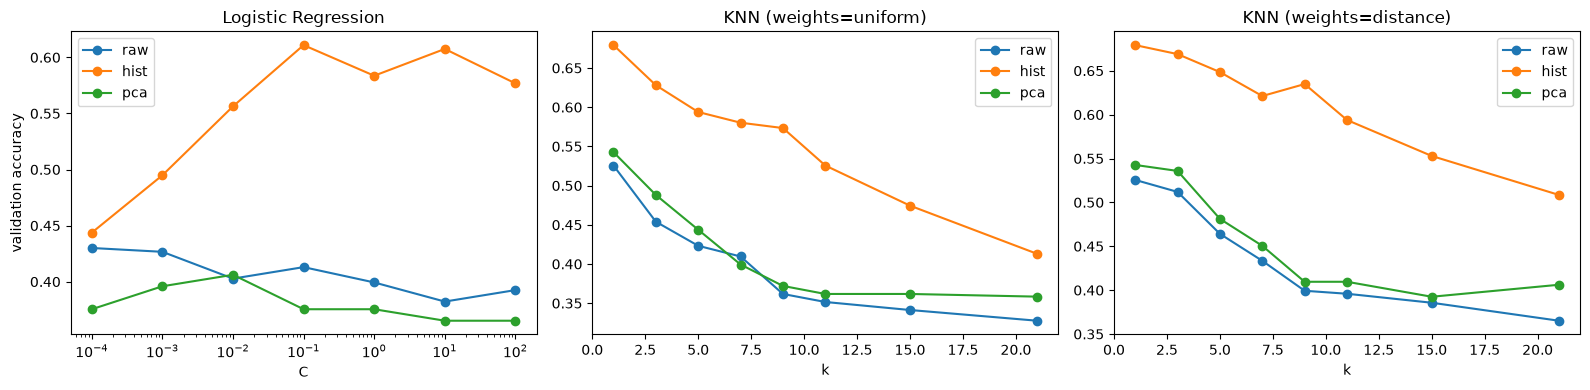

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for name in FS:
    d = lr_results[lr_results["features"] == name]
    ax[0].plot(d["x"], d["val_acc"], marker="o", label=name)
ax[0].set_xscale("log"); ax[0].set_xlabel("C"); ax[0].set_ylabel("validation accuracy")
ax[0].set_title("Logistic Regression"); ax[0].legend()

for ax_i, w in zip(ax[1:], ["uniform", "distance"]):
    for name in FS:
        d = knn_results[(knn_results["features"] == name) & (knn_results["weights"] == w)]
        ax_i.plot(d["x"], d["val_acc"], marker="o", label=name)
    ax_i.set_xlabel("k"); ax_i.set_title(f"KNN (weights={w})"); ax_i.legend()

plt.tight_layout(); plt.show()

## Best setting per model and feature set (chosen on validation accuracy)

In [5]:
results = pd.concat([lr_results, knn_results], ignore_index=True)
best = results.loc[results.groupby(["model", "features"])["val_acc"].idxmax()]
best = best[["model", "features", "param", "train_acc", "val_acc", "val_macro_f1"]].round(4)
print(best.to_string(index=False))

results.to_csv(EXP / "experiments_part_b.csv", index=False)
best.to_csv(EXP / "best_per_model_part_b.csv", index=False)

 model features          param  train_acc  val_acc  val_macro_f1
   KNN     hist k=1, w=uniform     1.0000   0.6792        0.6800
   KNN      pca k=1, w=uniform     1.0000   0.5427        0.5404
   KNN      raw k=1, w=uniform     1.0000   0.5256        0.5226
LogReg     hist          C=0.1     0.7749   0.6109        0.6103
LogReg      pca         C=0.01     0.7325   0.4061        0.4062
LogReg      raw       C=0.0001     0.6170   0.4300        0.4295
